# DIP Lab 04 (Final) – Phân đoạn tài liệu bằng Otsu + Morphology
**Input:** `data/document.png` · **Output:** bounding box cho các vùng TITLE / TEXT / PHOTO / QR CODE.

Các bước của đề:
1. Gray → Binary (**Otsu**)
2. Phát hiện QR (`cv2.QRCodeDetector`) → `qrcode_mask`
3. Xóa QR khỏi ảnh nhị phân: `cv2.subtract(binary, qrcode_mask)`
4. Tách vùng ảnh bằng morphology (structuring element + closing + contours) – **kích thước SE là then chốt**
5. Tách vùng chữ: `binary − photo_mask − qrcode_mask`
6. Vẽ bounding box

Điểm nổi bật: Otsu, dilate/erode/closing, tìm contour (BFS), bounding rect đều được **tự cài bằng NumPy**. OpenCV chỉ dùng để đọc/ghi ảnh, phát hiện QR và vẽ. Toàn bộ notebook chạy khoảng 1 phút.

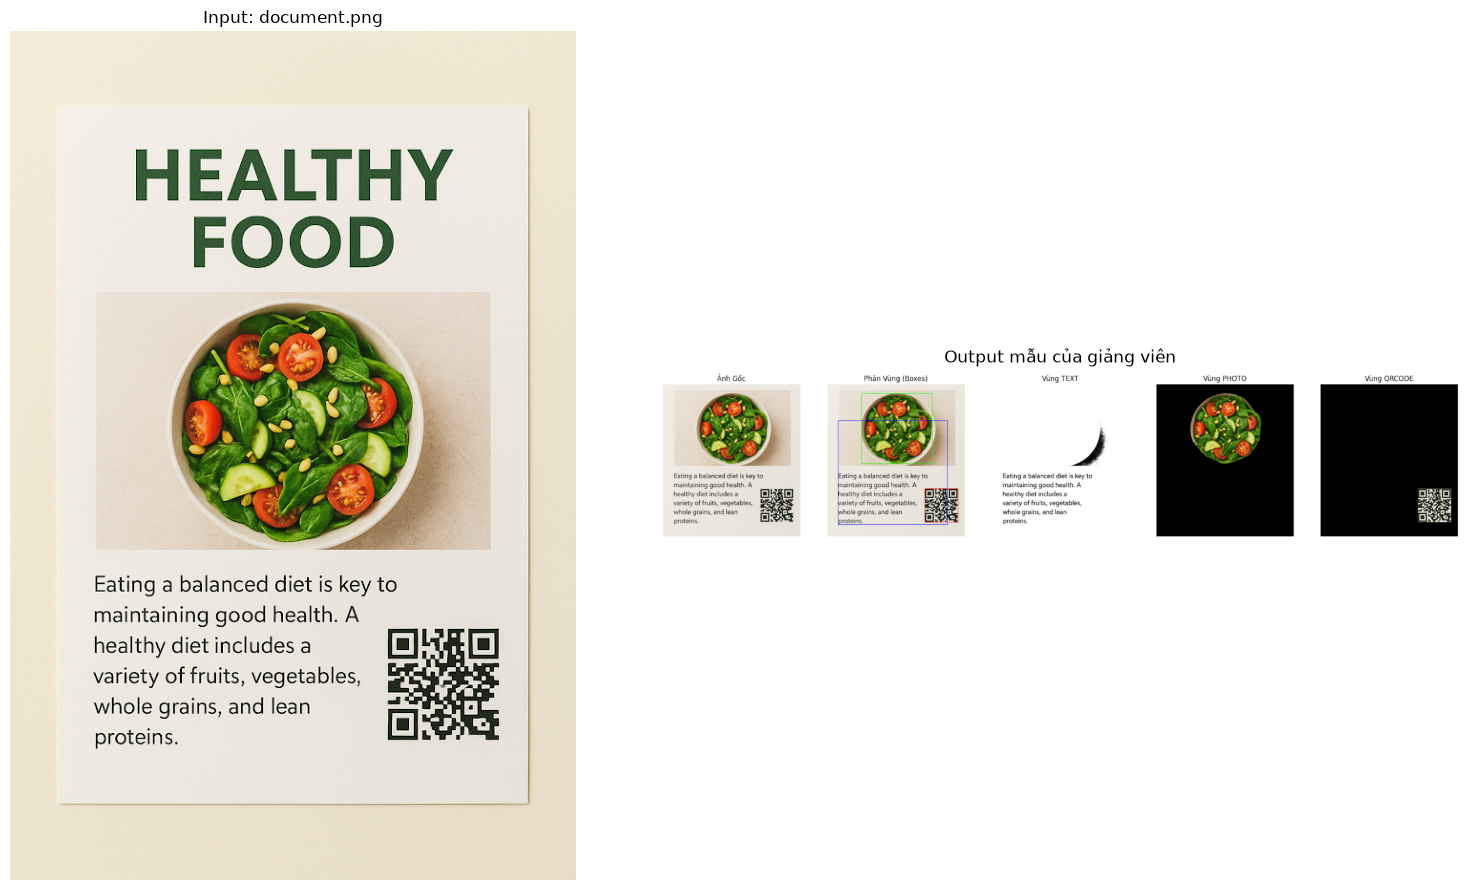

In [1]:
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGE_PATH = str(DATA_DIR / "document.png")


def show(*names, titles=None, figsize=(16, 9)):
    """Hiển thị ảnh: tham số là tên file trong outputs/ hoặc mảng ảnh BGR."""
    imgs = [cv2.imread(str(OUTPUT_DIR / n)) if isinstance(n, str) else n for n in names]
    fig, axes = plt.subplots(1, len(imgs), figsize=figsize, squeeze=False)
    for ax, img, title in zip(axes[0], imgs, titles or names):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
    plt.tight_layout()
    plt.show()


show(cv2.imread(IMAGE_PATH), cv2.imread(str(DATA_DIR / "reference_output.png")),
     titles=["Input: document.png", "Output mẫu của giảng viên"])

## 1. Các hàm tự cài (scratch)
| Hàm | Ý nghĩa |
|---|---|
| `_otsu_threshold_scratch` | Chọn ngưỡng t tối đa hóa phương sai giữa lớp `ω0·ω1·(μ0 − μ1)²`; pixel ≤ t → 255 (đảo để chữ/ảnh thành vùng trắng) |
| `_morphology_operation_scratch` | Dilate = max lân cận, Erode = min lân cận |
| `_morphology_ex_closing_scratch` | Closing = dilate → erode: lấp khe, nối mảng rời thành khối |
| `_find_contours_scratch` | Tìm vùng liên thông bằng BFS trên các pixel = 255 |
| `_bounding_rect_scratch`, `_contour_area_scratch` | Khung bao và diện tích (số pixel) |

In [2]:
def _get_structuring_element_scratch(size):
    """Tạo kernel toàn 1 (Structuing Element) dùng Numpy."""
    return np.ones(size, dtype=np.uint8)

def _morphology_operation_scratch(image, kernel, op='dilate'):
    """Triển khai Dilation hoặc Erosion 'chay' bằng cửa sổ trượt."""
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    
    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    output_img = np.zeros_like(image, dtype=image.dtype)
    
    for i in range(img_h):
        for j in range(img_w):
            neighborhood = padded_img[i:i+k_h, j:j+k_w]
            
            if op == 'dilate':
                output_img[i, j] = np.max(neighborhood)
            else:
                output_img[i, j] = np.min(neighborhood)
                
    return output_img

def _morphology_ex_closing_scratch(image, kernel):
    """Thực hiện phép Closing (Dilation sau đó Erosion) dùng hàm 'chay'."""
    dilated = _morphology_operation_scratch(image, kernel, op='dilate')
    closed = _morphology_operation_scratch(dilated, kernel, op='erode')
    return closed

def _find_contours_scratch(binary_image):
    """Tìm Contours/Connected Components 'chay' bằng thuật toán BFS."""
    H, W = binary_image.shape
    visited = np.zeros((H, W), dtype=bool)
    all_contours = []
    directions = [(0, 1), (0, -1), (1, 0), (-1, 0)]
    
    for r in range(H):
        for c in range(W):
            if binary_image[r, c] == 255 and not visited[r, c]:
                current_contour = []
                queue = [(r, c)]
                visited[r, c] = True
                
                while queue:
                    curr_r, curr_c = queue.pop(0)
                    current_contour.append((curr_c, curr_r)) # (x, y)
                    
                    for dr, dc in directions:
                        next_r, next_c = curr_r + dr, curr_c + dc
                        if (0 <= next_r < H and 0 <= next_c < W and 
                            binary_image[next_r, next_c] == 255 and 
                            not visited[next_r, next_c]):
                            visited[next_r, next_c] = True
                            queue.append((next_r, next_c))
                            
                if current_contour:
                    contour_array = np.array(current_contour, dtype=np.int32).reshape(-1, 1, 2)
                    all_contours.append(contour_array)
                    
    return all_contours, None 

def _bounding_rect_scratch(contour_points):
    """Tính bounding box (x, y, w, h) từ một tập hợp các điểm 'chay'."""
    if contour_points is None or len(contour_points) == 0:
        return (0, 0, 0, 0)
    
    points = contour_points.reshape(-1, 2) 
    x_min = np.min(points[:, 0])
    y_min = np.min(points[:, 1])
    x_max = np.max(points[:, 0])
    y_max = np.max(points[:, 1])

    return (x_min, y_min, x_max - x_min + 1, y_max - y_min + 1) 

def _contour_area_scratch(contour):
    """Tính diện tích contour bằng cách đếm số pixel (chay)."""
    return len(contour.reshape(-1, 2)) if contour is not None else 0

def _otsu_threshold_scratch(gray_image):
    """Thực hiện phân ngưỡng Otsu 'hoàn toàn chay'."""
    hist, _ = np.histogram(gray_image.flatten(), bins=256, range=[0, 256])
    total_pixels = gray_image.size
    probabilities = hist / total_pixels
    
    mu_T = np.sum(np.arange(256) * probabilities) 
    max_variance = 0
    best_threshold = 0
    omega0_t = 0 
    mu0_t = 0   
    
    for t in range(256):
        omega0_t += probabilities[t]
        if omega0_t == 0 or omega0_t == 1.0:
            continue
            
        mu0_t += t * probabilities[t]
        
        omega1_t = 1.0 - omega0_t
        
        mu1_t = (mu_T - mu0_t) / omega1_t if omega1_t != 0 else 0 
        
        current_variance = omega0_t * omega1_t * ((mu0_t / omega0_t) - mu1_t)**2
        
        if current_variance > max_variance:
            max_variance = current_variance
            best_threshold = t
            
    binary_img = np.zeros_like(gray_image, dtype=np.uint8) 
    binary_img[gray_image <= best_threshold] = 255
    return binary_img

def _bitwise_not_scratch(image):
    """Phép đảo ngược màu 'chay'."""
    return 255 - image

def _convert_color_gray_to_bgr_scratch(image):
    """Chuyển ảnh grayscale (1 kênh) sang BGR (3 kênh) dùng Numpy stack."""
    return np.stack([image, image, image], axis=2)

def _bitwise_and_scratch(image, mask):
    """Áp dụng mask 3 kênh lên ảnh 3 kênh dùng Numpy."""
    output = (image.astype(np.float32) * (mask.astype(np.float32) / 255.0)).astype(np.uint8)
    return output


def _draw_bbox_with_text(image, bbox, label, color):
    """Hàm hỗ trợ vẽ bounding box (vẫn dùng cv2 cho trực quan)."""
    x, y, w, h = bbox
    if w > 0 and h > 0:
        cv2.rectangle(image, (x, y), (x + w, y + h), color, 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        cv2.putText(image, label, (x, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

Kiểm chứng Otsu tự cài với OpenCV:

Ngưỡng OpenCV: 151 · Số pixel khác nhau: 0 / 527177


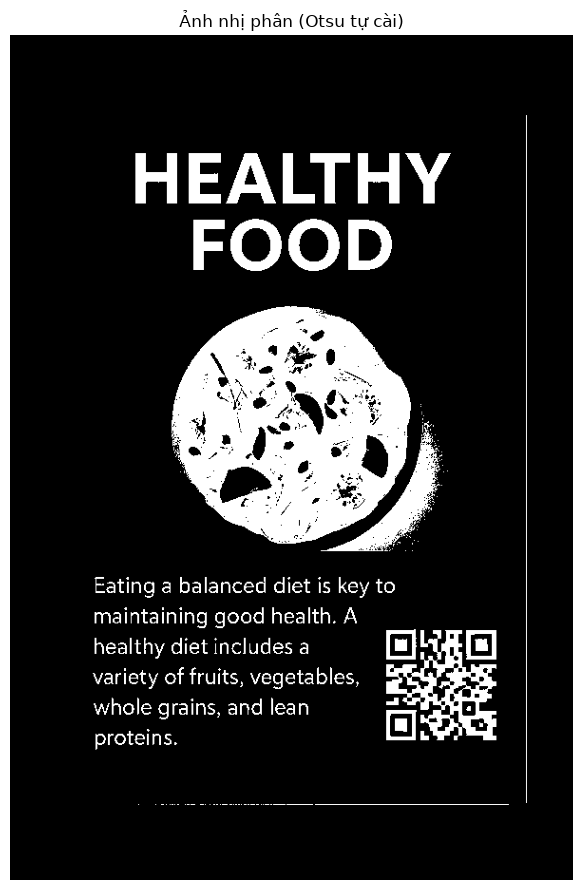

In [3]:
gray = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2GRAY)
binary_scratch = _otsu_threshold_scratch(gray)
t, binary_cv2 = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Ngưỡng OpenCV: {t:.0f} · Số pixel khác nhau: {(binary_scratch != binary_cv2).sum()} / {gray.size}")
show(binary_scratch, titles=["Ảnh nhị phân (Otsu tự cài)"], figsize=(8, 9))

## 2. Phân đoạn toàn bộ tài liệu (bounding box)
- Closing **15×15** gộp ảnh tô canh thành một khối → chọn contour **lớn nhất**, diện tích > 1 % ảnh, nằm dưới 15 % chiều cao (loại tiêu đề).
- Phần còn lại sau khi trừ QR và photo là chữ: phía **trên** ảnh là TITLE, phía **dưới** ảnh là CONTENT.

Đã lưu kết quả 1 (Phân đoạn đầy đủ) vào output_1_full_segmentation.png


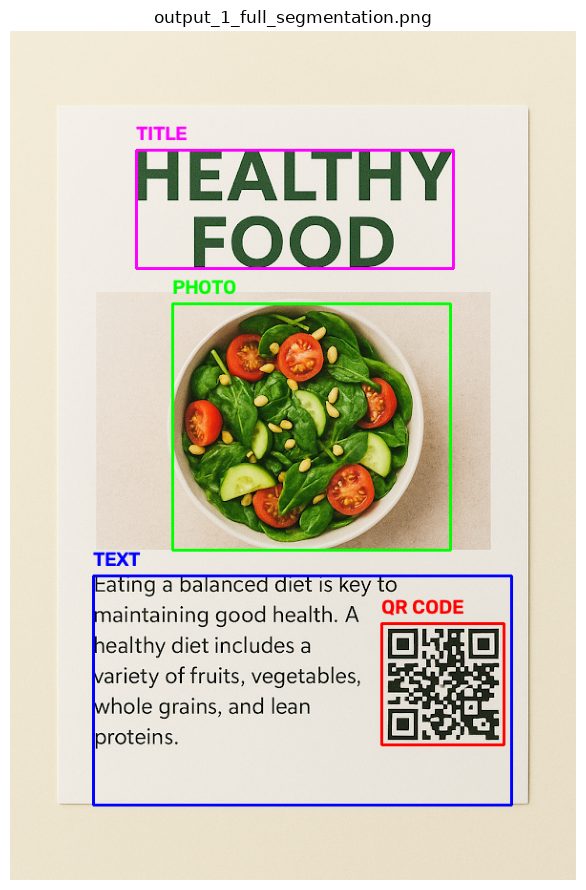

In [4]:
def segment_full_document_scratch(image_path):
    """
    Chức năng 1: Phân đoạn toàn bộ tài liệu (QR, Ảnh, Tiêu đề, Nội dung)
    (Gần giống đoạn code đầu tiên)
    """
    img = cv2.imread(image_path)
    if img is None:
        print(f"Lỗi: Không thể đọc ảnh từ đường dẫn {image_path}")
        return
        
    H, W = img.shape[:2]
    
    # 1. Input -> Gray Scale -> Binary (Otsu threshold Scratch)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    binary_img = _otsu_threshold_scratch(gray) 

    qr_detector = cv2.QRCodeDetector()
    _, points = qr_detector.detect(gray)
    qrcode_mask = np.zeros_like(gray, dtype=np.uint8)
    qrcode_bbox = (0, 0, 0, 0)
    
    if points is not None:
        points_flat = points.astype(np.int32).reshape(-1, 2)
        x_qr, y_qr, w_qr, h_qr = _bounding_rect_scratch(points_flat) 
        
        padding = 5
        x_p = max(0, x_qr - padding)
        y_p = max(0, y_qr - padding)
        x_end = min(W, x_p + w_qr + 2 * padding)
        y_end = min(H, y_p + h_qr + 2 * padding)
        qrcode_mask[y_p:y_end, x_p:x_end] = 255
        qrcode_bbox = (x_p, y_p, x_end - x_p, y_end - y_p)

    binary_img_no_qr = cv2.subtract(binary_img, qrcode_mask)

    # --- TÌM VÙNG ẢNH BẰNG MORPHOLOGY SCRACTH ---
    PHOTO_SE_SIZE = (15, 15)
    kernel = _get_structuring_element_scratch(PHOTO_SE_SIZE)
    morph_img = _morphology_ex_closing_scratch(binary_img_no_qr, kernel) 
    contours, _ = _find_contours_scratch(morph_img) 
    
    photo_mask = np.zeros_like(gray, dtype=np.uint8)
    photo_bbox = (0, 0, 0, 0)
    
    if contours:
        best_contour = None
        max_area = 0
        MIN_PHOTO_AREA = W * H * 0.01
        
        for contour in contours:
            x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour) # Dùng hàm Chay
            area = _contour_area_scratch(contour) # Dùng hàm Chay
            
            if area > max_area and area > MIN_PHOTO_AREA and y_c > H * 0.15:
                max_area = area
                best_contour = contour
                
        if best_contour is not None:
            x_b, y_b, w_b, h_b = _bounding_rect_scratch(best_contour)
            photo_mask[y_b:y_b+h_b, x_b:x_b+w_b] = 255
            photo_bbox = (x_b, y_b, w_b, h_b)

    # 5. Split Text region
    text_mask_full = cv2.subtract(binary_img_no_qr, photo_mask)
    
    # --- PHÂN ĐOẠN TIÊU ĐỀ/NỘI DUNG (Dựa trên vị trí Ảnh) ---
    x_photo_start, y_photo_start, w_photo, h_photo = photo_bbox
    y_photo_end = y_photo_start + h_photo
    y_threshold = y_photo_end + 10
    
    text_contours_full, _ = _find_contours_scratch(text_mask_full)
    
    valid_text_contours = [] # Nội dung
    header_contours = []     # Tiêu đề
    
    for contour in text_contours_full:
        x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour)
        if y_c >= y_threshold:
            valid_text_contours.append(contour)
        elif (y_c + h_c) < y_photo_start:
            if _contour_area_scratch(contour) > 100:
                header_contours.append(contour)

    # Hộp giới hạn Nội dung
    text_bbox = (0, 0, 0, 0)
    if valid_text_contours:
        text_points = np.concatenate(valid_text_contours)
        if len(text_points) > 0:
            text_bbox = _bounding_rect_scratch(text_points)
            
    # Hộp giới hạn Tiêu đề
    header_bbox = (0, 0, 0, 0)
    if header_contours:
        header_points = np.concatenate(header_contours)
        if len(header_points) > 0:
            header_bbox = _bounding_rect_scratch(header_points)

    # --- Giai đoạn 3: Trực quan hóa (Bounding Boxes) ---
    output_img = img.copy()
    COLORS = {'Photo': (0, 255, 0), 'Text': (255, 0, 0), 'QR': (0, 0, 255), 'Header': (255, 0, 255)}
    
    _draw_bbox_with_text(output_img, header_bbox, 'TITLE', COLORS['Header'])
    _draw_bbox_with_text(output_img, photo_bbox, 'PHOTO', COLORS['Photo'])
    _draw_bbox_with_text(output_img, text_bbox, 'TEXT', COLORS['Text'])
    _draw_bbox_with_text(output_img, qrcode_bbox, 'QR CODE', COLORS['QR'])
    
    cv2.imwrite(os.path.join(OUTPUT_DIR, "output_1_full_segmentation.png"), output_img)
    print("Đã lưu kết quả 1 (Phân đoạn đầy đủ) vào output_1_full_segmentation.png")


segment_full_document_scratch(IMAGE_PATH)
show("output_1_full_segmentation.png")

## 3. Chỉ giữ phần nội dung chữ (sắc nét, nền trắng)

 Đã lưu kết quả 2 (Text Nội dung Sắc nét) vào output_2_text_content_only.png


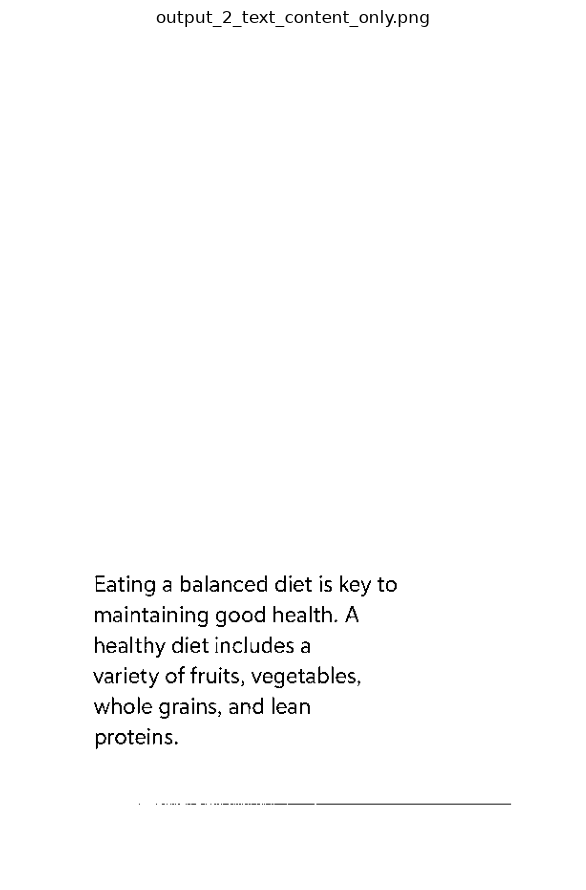

In [5]:
def segment_text_content_only_scratch(image_path):
    """
    Chức năng 2: Tách vùng Text Nội dung Sắc nét
    (Gần giống đoạn code thứ hai)
    """
    img = cv2.imread(image_path)
    if img is None:
        return
        
    H, W = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    binary_img = _otsu_threshold_scratch(gray)

    qr_detector = cv2.QRCodeDetector()
    _, points = qr_detector.detect(gray)
    qrcode_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if points is not None:
        points_flat = points.astype(np.int32).reshape(-1, 2)
        x, y, w, h = _bounding_rect_scratch(points_flat)
        padding = 5
        x_p = max(0, x - padding)
        y_p = max(0, y - padding)
        x_end = min(W, x + w + padding)
        y_end = min(H, y + h + padding)
        qrcode_mask[y_p:y_end, x_p:x_end] = 255
        
    binary_img_no_qr = cv2.subtract(binary_img, qrcode_mask)

    SE_SIZE = (7, 7)
    kernel = _get_structuring_element_scratch(SE_SIZE)
    morph_img = _morphology_ex_closing_scratch(binary_img_no_qr, kernel)
    contours, _ = _find_contours_scratch(morph_img)
    
    photo_mask = np.zeros_like(gray, dtype=np.uint8)
    photo_bbox = (0, 0, 0, 0)
    
    if contours:
        best_contour = None
        max_area = 0
        for contour in contours:
            area = _contour_area_scratch(contour)
            x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour)
            if area > max_area and y_c > H * 0.15: 
                max_area = area
                best_contour = contour
                
        if best_contour is not None:
            x_b, y_b, w_b, h_b = _bounding_rect_scratch(best_contour)
            photo_mask[y_b:y_b+h_b, x_b:x_b+w_b] = 255
            photo_bbox = (x_b, y_b, w_b, h_b)

    text_mask_full = cv2.subtract(binary_img_no_qr, photo_mask) 
    
    _, y_photo_start, w_photo, h_photo = photo_bbox
    y_threshold = y_photo_start + h_photo + 10
    
    text_contours_full, _ = _find_contours_scratch(text_mask_full)
    all_content_text_points = []
    
    for contour in text_contours_full:
        x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour)
        if y_c >= y_threshold: # Lọc những contour nằm dưới vùng ảnh
            all_content_text_points.append(contour)

    # Lấy Bounding Box SẮC NÉT cho Text Nội dung
    text_content_bbox = (0, 0, 0, 0)
    if all_content_text_points:
        combined_points = np.concatenate(all_content_text_points)
        text_content_bbox = _bounding_rect_scratch(combined_points)

    x_t, y_t, w_t, h_t = text_content_bbox
    output_text_only = np.full(img.shape, 255, dtype=np.uint8) # Ảnh nền trắng
    
    if w_t > 0 and h_t > 0:
        # Lấy vùng chữ từ ảnh nhị phân SẠCH ban đầu
        text_region_clean = binary_img_no_qr[y_t:y_t+h_t, x_t:x_t+w_t]
        # Đảo ngược màu (chữ đen trên nền trắng)
        text_region_clean_inv = _bitwise_not_scratch(text_region_clean)
        text_region_clean_inv_3ch = _convert_color_gray_to_bgr_scratch(text_region_clean_inv)
        
        output_text_only[y_t:y_t+h_t, x_t:x_t+w_t] = text_region_clean_inv_3ch
        
    cv2.imwrite(os.path.join(OUTPUT_DIR, "output_2_text_content_only.png"), output_text_only)
    print(" Đã lưu kết quả 2 (Text Nội dung Sắc nét) vào output_2_text_content_only.png")


segment_text_content_only_scratch(IMAGE_PATH)
show("output_2_text_content_only.png")

## 4. Giữ cả tiêu đề và nội dung chữ

Đã lưu kết quả (Text + Title Sắc nét, không box) vào output_2_text_and_title_only.png


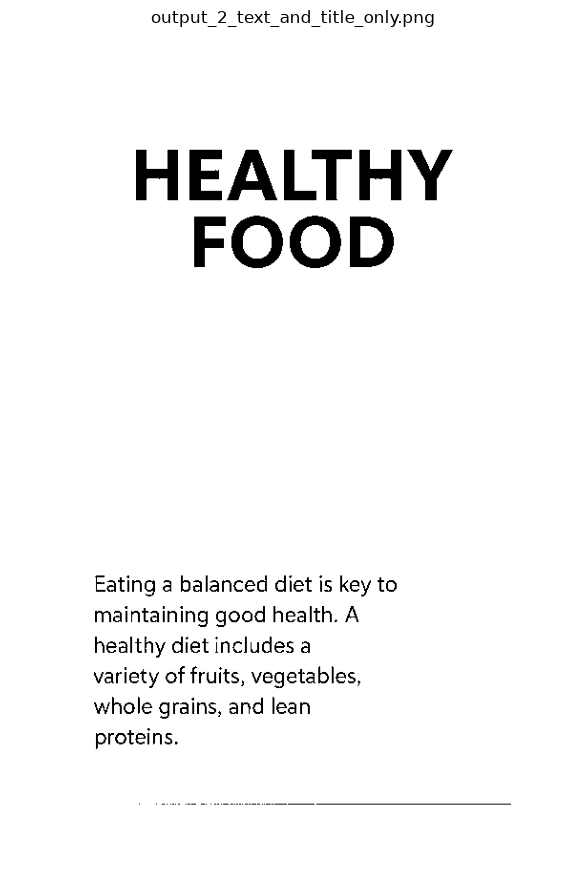

In [6]:
def segment_text_and_title_scratch(image_path):
    """
    Tách vùng Text Nội dung Sắc nét VÀ Vùng Tiêu đề Sắc nét.
    (Là phiên bản chính thức, không vẽ box trực quan)
    """
    img = cv2.imread(image_path)
    if img is None:
        print(f"Lỗi: Không thể đọc ảnh từ đường dẫn {image_path}")
        return
        
    H, W = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    binary_img = _otsu_threshold_scratch(gray) 

    # --- 1. Loại bỏ QR Code (Dùng QR Detector) ---
    qr_detector = cv2.QRCodeDetector()
    _, points = qr_detector.detect(gray)
    qrcode_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if points is not None:
        points_flat = points.astype(np.int32).reshape(-1, 2)
        x, y, w, h = _bounding_rect_scratch(points_flat)
        padding = 5
        qrcode_mask[max(0, y - padding):min(H, y + h + padding), 
                    max(0, x - padding):min(W, x + w + padding)] = 255
                    
    binary_img_no_qr = cv2.subtract(binary_img, qrcode_mask)

    # --- 2. Tách Vùng Ảnh (Photo) ---
    SE_SIZE = (7, 7)
    kernel = _get_structuring_element_scratch(SE_SIZE)
    morph_img = _morphology_ex_closing_scratch(binary_img_no_qr, kernel)
    contours, _ = _find_contours_scratch(morph_img)
    
    photo_bbox = (0, 0, 0, 0)
    
    if contours:
        best_contour = None
        max_area = 0
        for contour in contours:
            area = _contour_area_scratch(contour)
            x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour)
            if area > max_area and y_c > H * 0.15: 
                max_area = area
                best_contour = contour
                
        if best_contour is not None:
            photo_bbox = _bounding_rect_scratch(best_contour)

    # Tạo text_mask_full bằng cách loại bỏ vùng ảnh (Bounding Box)
    photo_mask = np.zeros_like(gray, dtype=np.uint8)
    x_b, y_b, w_b, h_b = photo_bbox
    if w_b > 0 and h_b > 0:
        photo_mask[y_b:y_b+h_b, x_b:x_b+w_b] = 255
        
    text_mask_full = cv2.subtract(binary_img_no_qr, photo_mask) 
    
    y_photo_start = y_b
    y_photo_end = y_b + h_b
    y_threshold_content = y_photo_end + 10 # Ngưỡng cho CONTENT
    
    text_contours_full, _ = _find_contours_scratch(text_mask_full)
    
    content_contours = []
    header_contours = []
    MIN_CONTOUR_AREA = 50

    for contour in text_contours_full:
        x_c, y_c, w_c, h_c = _bounding_rect_scratch(contour)
        area = _contour_area_scratch(contour)
        
        if area < MIN_CONTOUR_AREA:
            continue
            
        if y_c >= y_threshold_content:
            content_contours.append(contour)
        elif (y_c + h_c) < y_photo_start:
            header_contours.append(contour)  

    header_bbox = (0, 0, 0, 0)
    if header_contours:
        header_points = np.concatenate(header_contours)
        if len(header_points) > 0:
            header_bbox = _bounding_rect_scratch(header_points)
            
    content_bbox = (0, 0, 0, 0)
    if content_contours:
        content_points = np.concatenate(content_contours)
        if len(content_points) > 0:
            content_bbox = _bounding_rect_scratch(content_points)

    output_text_and_title = np.full(img.shape, 255, dtype=np.uint8) 
    
    def _apply_text_region(bbox, output_img, source_binary):
        x_t, y_t, w_t, h_t = bbox
        if w_t > 0 and h_t > 0:
            text_region_clean = source_binary[y_t:y_t+h_t, x_t:x_t+w_t]
            text_region_clean_inv = _bitwise_not_scratch(text_region_clean) 
            text_region_clean_inv_3ch = _convert_color_gray_to_bgr_scratch(text_region_clean_inv)
            output_img[y_t:y_t+h_t, x_t:x_t+w_t] = text_region_clean_inv_3ch
    
    _apply_text_region(header_bbox, output_text_and_title, binary_img_no_qr) 
    _apply_text_region(content_bbox, output_text_and_title, binary_img_no_qr)

    OUTPUT_FILENAME = "output_2_text_and_title_only.png"
    cv2.imwrite(os.path.join(OUTPUT_DIR, OUTPUT_FILENAME), output_text_and_title)
    
    print(f"Đã lưu kết quả (Text + Title Sắc nét, không box) vào {OUTPUT_FILENAME}")


segment_text_and_title_scratch(IMAGE_PATH)
show("output_2_text_and_title_only.png")

## 5. Chỉ giữ vùng ảnh
- SE **ngang 40×3** nối các ký tự cùng dòng thành thanh dài → lọc tỉ lệ rộng/cao > 3 để nhận diện dòng chữ.
- Trừ dòng chữ đi, lấy khối lớn nhất còn lại, closing **50×50** để lấp kín vùng ảnh.

 Đã lưu kết quả 3 (Vùng Ảnh Tô Canh) vào output_3_photo_only.png


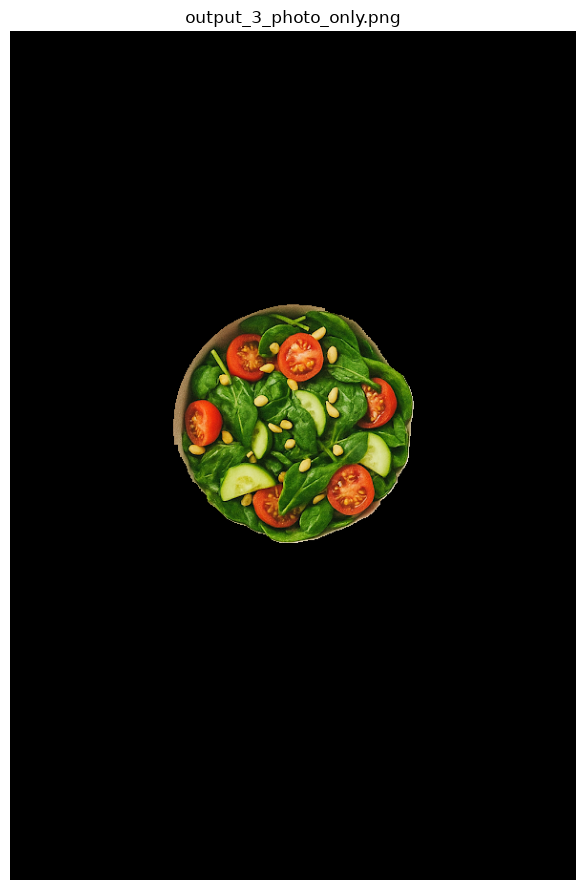

In [7]:
def segment_photo_only_scratch(image_path):
    """
    Chức năng 3: Tách vùng ảnh tô canh (Bowl Photo)
    (Gần giống đoạn code thứ ba - Dùng Morphology và Lọc hình dạng)
    """
    img = cv2.imread(image_path)
    if img is None:
        return
        
    H, W = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    binary_img = _otsu_threshold_scratch(gray) 

    # QR code detector và tạo qrcode_mask (Loại bỏ QR - Giả định dùng QR detector cho độ chính xác cao)
    qr_detector = cv2.QRCodeDetector()
    _, points = qr_detector.detect(gray)
    qrcode_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if points is not None:
        points_flat = points.astype(np.int32).reshape(-1, 2)
        x, y, w, h = _bounding_rect_scratch(points_flat)
        padding = 5
        qrcode_mask[max(0, y - padding):min(H, y + h + padding), 
                    max(0, x - padding):min(W, x + w + padding)] = 255
                    
    binary_img_no_qr = cv2.subtract(binary_img, qrcode_mask)

    # Tách Vùng TEXT bằng Morphology ngang (Horizontal Morphology Scratch)
    TEXT_KERNEL_SIZE = (40, 3)
    kernel_text = _get_structuring_element_scratch(TEXT_KERNEL_SIZE)
    text_morph = _morphology_ex_closing_scratch(binary_img_no_qr, kernel_text)
    text_contours, _ = _find_contours_scratch(text_morph)
    
    text_mask = np.zeros_like(gray, dtype=np.uint8)
    MIN_ASPECT_RATIO = 3.0 # Tỷ lệ rộng/cao lớn
    MIN_AREA = 100
    
    for contour in text_contours:
        x, y, w, h = _bounding_rect_scratch(contour)
        area = _contour_area_scratch(contour)
        aspect_ratio = w / h if h > 0 else 999
        
        if aspect_ratio > MIN_ASPECT_RATIO and area > MIN_AREA:
            cv2.rectangle(text_mask, (x, y), (x + w, y + h), 255, -1) # Dùng cv2 để fill mask

    # Tách Vùng PHOTO (Phần còn lại)
    photo_candidate_mask = cv2.subtract(binary_img_no_qr, text_mask) 
    
    photo_contours, _ = _find_contours_scratch(photo_candidate_mask)
    photo_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if photo_contours:
        largest_contour = max(photo_contours, key=_contour_area_scratch)

        points = largest_contour.reshape(-1, 2)
        for x, y in points:
            if 0 <= y < H and 0 <= x < W:
                photo_mask[y, x] = 255 

        FILL_KERNEL_SIZE = (50, 50)
        fill_kernel = _get_structuring_element_scratch(FILL_KERNEL_SIZE)
        photo_mask = _morphology_ex_closing_scratch(photo_mask, fill_kernel)
        
    photo_mask_3ch = _convert_color_gray_to_bgr_scratch(photo_mask)
    output_photo_only = _bitwise_and_scratch(img, photo_mask_3ch)
    
    cv2.imwrite(os.path.join(OUTPUT_DIR, "output_3_photo_only.png"), output_photo_only)
    print(" Đã lưu kết quả 3 (Vùng Ảnh Tô Canh) vào output_3_photo_only.png")


segment_photo_only_scratch(IMAGE_PATH)
show("output_3_photo_only.png")

## 6. Chỉ giữ vùng QR code

Đã lưu kết quả 4 (Vùng QR Code) vào output_4_qrcode_only.png


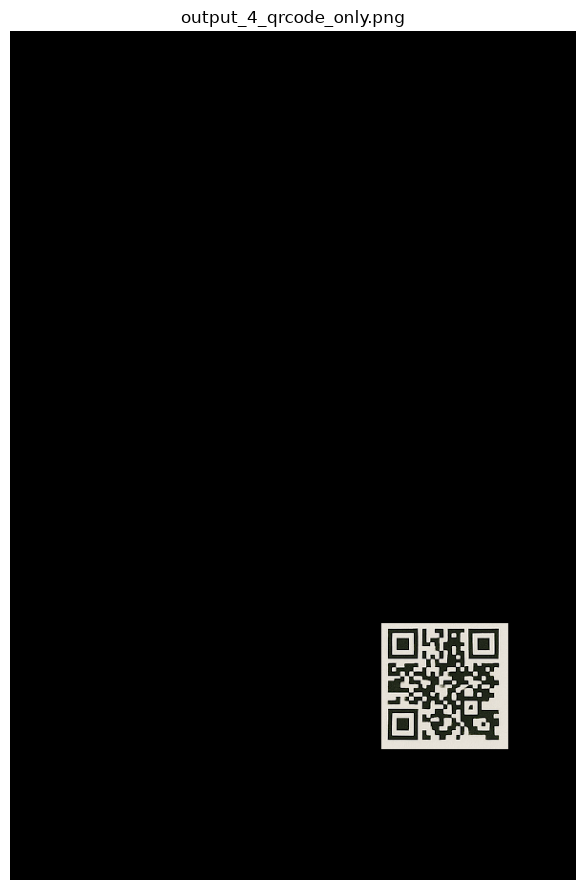

In [8]:
def segment_qrcode_only_scratch(image_path):
    """
    Chức năng 4: Tách vùng QR code Sắc nét
    (Gần giống đoạn code thứ tư)
    """
    img = cv2.imread(image_path)
    if img is None:
        return
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W = img.shape[:2]
    
    qr_detector = cv2.QRCodeDetector()
    _, points = qr_detector.detect(gray)

    qrcode_mask = np.zeros_like(gray, dtype=np.uint8)
    
    if points is not None:
        points_flat = points.astype(np.int32).reshape(-1, 2)
        x, y, w, h = _bounding_rect_scratch(points_flat) 
        
        padding = 5
        x_p = max(0, x - padding)
        y_p = max(0, y - padding)
        x_end = min(W, x + w + 2 * padding)
        y_end = min(H, y + h + 2 * padding)
        
        qrcode_mask[y_p:y_end, x_p:x_end] = 255

    # Chuyển mask (1 kênh) sang 3 kênh màu và áp dụng Bitwise AND (dùng hàm Chay)
    qrcode_mask_3ch = _convert_color_gray_to_bgr_scratch(qrcode_mask)
    output_qrcode_only = _bitwise_and_scratch(img, qrcode_mask_3ch)

    cv2.imwrite(os.path.join(OUTPUT_DIR, "output_4_qrcode_only.png"), output_qrcode_only)
    print("Đã lưu kết quả 4 (Vùng QR Code) vào output_4_qrcode_only.png")


segment_qrcode_only_scratch(IMAGE_PATH)
show("output_4_qrcode_only.png")